# Weight distributions: backpropagation vs. our method

Every sweep stores the adapted weights of every method at every noise level. For each benchmark this notebook draws the
distribution of the weight values of the full-retraining (backpropagation) model as a violin at every noise level, and
overlays the violin of our method's weights at the same noise level. The clean model $\theta_0$ that every run starts
from is shown at noise 0. Only parameters are used (batch-norm running statistics are buffers and are left out).
Nothing is hardcoded: the noise levels and files are discovered from the `weights_*` folders.

In [1]:
import re
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Ellipse

/home/rahman2/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
FONT_FAMILY         = "DejaVu Sans"   # e.g. "serif", "Times New Roman", "Arial", ...
BASE_FONTSIZE       = 25              # default text size (titles, legend title, ...)
AXIS_LABEL_FONTSIZE = 17              # x/y axis label size
AXIS_TICK_FONTSIZE  = 17              # x/y tick label size
plt.rcParams.update({
    "font.family":     FONT_FAMILY,
    "font.size":       BASE_FONTSIZE,
    "axes.labelsize":  AXIS_LABEL_FONTSIZE,
    "axes.titlesize":  BASE_FONTSIZE + 1,
    "xtick.labelsize": AXIS_TICK_FONTSIZE,
    "ytick.labelsize": AXIS_TICK_FONTSIZE,
    "legend.fontsize": BASE_FONTSIZE - 3,
})

## Configuration

In [3]:
# Model folder -> figure label. The order here is the order of the figures.
MODELS = {
    "lenet5_mnist":             "LeNet5/MNIST",
    "resnet20_cifar10":         "ResNet20/CIFAR10",
    "mobilenetv1_tinyimagenet": "MobileNet-v1/Tiny ImageNet",
}

BASELINE_DIR     = "weights_baselines"                 # per model folder
WEIGHTS_DIR_GLOB = "weights_*"                         # one folder per method (plus the baselines)
CHECKPOINT_RE    = re.compile(r"^(?P<method>.+?)_var_(?P<var>\d+(?:\.\d+)?)\.pth$")   # <method>_var_<noise variance>.pth

# Checkpoint-name prefix -> legend label
DISPLAY_NAMES = {"full_retrain": "Backpropagation", "bolster": "Ours", "lmc_spsa": "LMC", "smezo_spsa": "SMEZO",
                 "pepita": "PEPITA", "scff": "SCFF", "bp_fc": "BP-FC"}
REFERENCE_METHOD = "Backpropagation"     # drawn first (its noise-0 checkpoint is the clean model theta_0)
COMPARE_METHOD   = "Ours"                # drawn on top of the reference

COLORS = {"Backpropagation": "tab:blue", "Ours": "red", "theta0": "0.45"}
ALPHA  = 0.45                            # violin transparency, so the overlap stays visible

BUFFER_SUFFIXES  = ("running_mean", "running_var", "num_batches_tracked")   # batch-norm buffers: not parameters
MAX_SAMPLES      = 200_000               # weights per violin (random subsample of larger models; the KDE is slow otherwise)
Y_PERCENTILES    = (0.5, 99.5)           # y-range: central part of all values shown (the far tails would flatten the violins)
# y-axis per model folder: None -> linear; a number t -> arcsinh(w / t) scale (linear within about +-t, logarithmic beyond),
# for models whose weights pile up near zero with long tails (MobileNet: most weights are within 1e-4 of zero)
Y_ASINH          = {"mobilenetv1_tinyimagenet": 1e-3}
VIOLIN_WIDTH     = 0.08                  # in noise-variance units (the levels are 0.1 apart)
FIGSIZE          = (8, 4.5)

OUTPUT_DIR  = Path("figures")
OUTPUT_STEM = "weight_distribution"

## Load the weights

In [4]:
def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from `start` until a folder is found that contains the model folders."""
    for candidate in (start, *start.parents):
        if all((candidate / m).is_dir() for m in MODELS):
            return candidate
    raise FileNotFoundError(f"model folders {list(MODELS)} not found in {start} or its parents")


def load_weights(path: Path) -> np.ndarray:
    """All parameter values of a state dict as one float64 array (buffers left out)."""
    state = torch.load(path, map_location="cpu", weights_only=False)
    parts = [v.detach().to(torch.float64).reshape(-1) for k, v in state.items()
             if torch.is_tensor(v) and v.dtype.is_floating_point and not k.endswith(BUFFER_SUFFIXES)]
    return torch.cat(parts).numpy()


def discover_checkpoints(mdir: Path) -> dict:
    """{display name: {noise variance: path}} from every weights_* folder of a model folder."""
    found = {}
    for wdir in sorted(p for p in mdir.glob(WEIGHTS_DIR_GLOB) if p.is_dir()):
        for f in sorted(wdir.glob("*.pth")):
            m = CHECKPOINT_RE.match(f.name)
            if m:
                found.setdefault(DISPLAY_NAMES.get(m["method"], m["method"]), {})[float(m["var"])] = f
    return found


def subsample(w: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    return w if w.size <= MAX_SAMPLES else rng.choice(w, MAX_SAMPLES, replace=False)


PROJECT_ROOT = find_project_root()
print(f"project root: {PROJECT_ROOT}\n")

data = {}      # model -> dict(label, noises, ref: {noise: values}, cmp: {noise: values}, theta0: values)
rng = np.random.default_rng(0)
for model_dir, label in MODELS.items():
    ckpts = discover_checkpoints(PROJECT_ROOT / model_dir)
    for m in (REFERENCE_METHOD, COMPARE_METHOD):
        if m not in ckpts:
            raise FileNotFoundError(f"no {m!r} checkpoints in {model_dir}")
    noises = sorted(n for n in ckpts[REFERENCE_METHOD] if n > 0 and n in ckpts[COMPARE_METHOD])
    theta0 = load_weights(ckpts[REFERENCE_METHOD][0.0]) if 0.0 in ckpts[REFERENCE_METHOD] else None
    ref = {n: load_weights(ckpts[REFERENCE_METHOD][n]) for n in noises}
    cmp = {n: load_weights(ckpts[COMPARE_METHOD][n]) for n in noises}
    data[model_dir] = dict(label=label, noises=noises, n_params=ref[noises[0]].size,
                           theta0=None if theta0 is None else subsample(theta0, rng),
                           ref={n: subsample(v, rng) for n, v in ref.items()},
                           cmp={n: subsample(v, rng) for n, v in cmp.items()})
    print(f"== {label}: {ref[noises[0]].size:,} parameters, noise levels {noises[0]:g}..{noises[-1]:g} "
          f"({len(noises)} levels), {REFERENCE_METHOD} vs {COMPARE_METHOD}")
    for n in noises:
        print(f"   sigma^2 = {n:<4g}  {REFERENCE_METHOD}: mean {ref[n].mean():+.4f} std {ref[n].std():.4f}   "
              f"{COMPARE_METHOD}: mean {cmp[n].mean():+.4f} std {cmp[n].std():.4f}")
    print()

project root: /home/rahman2/GIT/BOLSTER

== LeNet5/MNIST: 61,706 parameters, noise levels 0.1..1 (10 levels), Backpropagation vs Ours
   sigma^2 = 0.1   Backpropagation: mean +0.0002 std 0.0868   Ours: mean +0.0001 std 0.0874
   sigma^2 = 0.2   Backpropagation: mean +0.0001 std 0.0867   Ours: mean +0.0002 std 0.0876
   sigma^2 = 0.3   Backpropagation: mean +0.0001 std 0.0867   Ours: mean +0.0002 std 0.0876
   sigma^2 = 0.4   Backpropagation: mean +0.0001 std 0.0866   Ours: mean +0.0002 std 0.0876
   sigma^2 = 0.5   Backpropagation: mean +0.0001 std 0.0866   Ours: mean +0.0002 std 0.0877
   sigma^2 = 0.6   Backpropagation: mean +0.0000 std 0.0865   Ours: mean +0.0002 std 0.0877
   sigma^2 = 0.7   Backpropagation: mean -0.0002 std 0.0865   Ours: mean +0.0002 std 0.0878
   sigma^2 = 0.8   Backpropagation: mean -0.0023 std 0.0875   Ours: mean +0.0002 std 0.0878
   sigma^2 = 0.9   Backpropagation: mean -0.0044 std 0.0893   Ours: mean +0.0002 std 0.0879
   sigma^2 = 1     Backpropagation: me

## Layer-wise cosine similarity to backpropagation vs. accuracy recovered

At every noise level, every method is compared with the backpropagation model of the same noise level: layer by layer,
for each parameter-owning layer $g$ the cosine similarity $\cos(\theta_{m,g}, \theta_{\mathrm{BP},g})$, and the accuracy it
retains relative to backpropagation (from the result spreadsheets). Each method is one marker at x = the accuracy
retained **averaged over the noise levels** and y = the **median** of the cosine similarities of all layers at all noise
levels. Behind it, a violin shows the distribution of those cosine similarities and whiskers reach the furthest value
within 1.5 interquartile ranges of the first and third quartiles. The violin is a Gaussian KDE reflected at $-1$ and $1$,
so it never leaves the range of a cosine; its tails run `COS_VIOLIN_CUT` bandwidths past the smallest and largest value.
Methods closer together than one violin width are drawn as half violins side by side, so neither hides the other.
Backpropagation itself is the reference at (100 %, 1). `CLUSTER_NOISES` selects the noise levels (all of them by
default). The first cell defines the computation and the drawing, then one cell per benchmark calls it with its own axis
limits. A benchmark whose methods crowd together can pass `zoom` to add a magnified inset of that region (LeNet: the
methods whose cosines all sit just below 1).

In [88]:
import pandas as pd

# ---- settings for this plot ----
CLUSTER_NOISES   = None                 # noise variances pooled into one figure; None -> every level > 0 found
RESULTS_DIR_GLOB = "results_*"          # per model folder: the spreadsheets with the accuracies (sheet `long`)
SHEET_NAME       = "long"
ACC_COL          = "accuracy"
ACC_LABELS       = {"Full retrain": "Backpropagation", "Init (no retrain)": "No retrain", "BOLSTER": "Ours",
                    "LMC-SPSA": "LMC", "Sparse-MeZO": "SMEZO"}        # spreadsheet labels -> display names
CLUSTER_EXCLUDE  = {"BP-FC"}
CLUSTER_COLORS   = {"No retrain": "0.45", "Ours": "tab:green", "LMC": "tab:gray", "SMEZO": "tab:purple",
                    "PEPITA": "tab:orange", "SCFF": "tab:red", "Backpropagation": "tab:blue"}


# COLORS = {
#     "Ours":            "tab:green",
#     "Backpropagation": "tab:blue",
#     "No retrain":      "black",
#     "SCFF":            "tab:red",
#     "PEPITA":          "tab:orange",
#     "SMEZO":           "tab:purple",
#     "LMC":             "tab:gray",
# }
CLUSTER_MARKERS  = {"No retrain": "x", "Ours": "*", "LMC": "o", "SMEZO": "s", "PEPITA": "^", "SCFF": "D"}
CLUSTER_FIGSIZE  = (6, 5)
CLUSTER_STEM     = "layer_cosine_vs_accuracy"
SHOW_NO_RETRAIN  = False                # also draw the unadapted clean model
CAP_WIDTH        = 1.5                  # default width of the whisker caps (accuracy points)
WHISKER_IQR      = 1.5                  # whiskers reach the furthest value within this many IQRs of the quartiles
COS_VIOLIN_WIDTH = 4.0                  # default width of the cosine violins (accuracy points)
COS_VIOLIN_ALPHA = 0.25
COS_VIOLIN_CUT   = 2.0                  # the violin's KDE runs this many bandwidths past the smallest and largest value,
                                        # so its ends taper off, but never past -1 or 1
INSET_MARKER_SCALE = 0.4                # marker size in a zoom inset, relative to the main axes

_SUFFIX_RE    = re.compile(r"\s*\([^()]*\)\s*$")       # trailing "(...)" e.g. "(T=1.0,10ep)"
_TIMESTAMP_RE = re.compile(r"(\d{8}_\d{6})")


def _acc_label(raw) -> str:
    raw = str(raw).strip()
    if raw in ACC_LABELS:
        return ACC_LABELS[raw]
    base = _SUFFIX_RE.sub("", raw)
    return ACC_LABELS.get(base, base)


def load_accuracies(mdir: Path) -> pd.Series:
    # accuracy per (method, noise) from the newest xlsx of every results_* folder; rows reported by several
    # files (the baselines) are taken from the bolster file first
    frames = []
    for rdir in sorted(p for p in mdir.glob(RESULTS_DIR_GLOB) if p.is_dir()):
        files = [f for f in rdir.glob("*.xlsx") if not f.name.startswith("~$")]
        if not files:
            continue
        f = max(files, key=lambda f: ((_TIMESTAMP_RE.search(f.stem) or [""])[0], f.stat().st_mtime))
        df = pd.read_excel(f, sheet_name=SHEET_NAME)
        df["method"] = df["method"].map(_acc_label)
        df["noise"] = df["noise_level"].map(lambda v: float(str(v).rstrip("%")) / 100 if str(v).endswith("%") else float(v))
        df["prio"] = 0 if "bolster" in rdir.name else 1
        frames.append(df[["method", "noise", ACC_COL, "prio"]])
    df = pd.concat(frames).sort_values("prio")
    return df.groupby(["method", "noise"], sort=False)[ACC_COL].first()


def params_by_layer(path: Path) -> dict:
    # {layer (parameter-owning module): flat float64 tensor of its parameters}, buffers left out
    state = torch.load(path, map_location="cpu", weights_only=False)
    layers = {}
    for k, v in state.items():
        if torch.is_tensor(v) and v.dtype.is_floating_point and not k.endswith(BUFFER_SUFFIXES):
            layers.setdefault(k.rsplit(".", 1)[0], []).append(v.detach().to(torch.float64).reshape(-1))
    return {g: torch.cat(v) for g, v in layers.items()}


def layer_cos(a: dict, b: dict) -> dict:
    # cosine similarity per layer between the two weight vectors
    return {g: float(a[g] @ b[g] / (a[g].norm() * b[g].norm())) for g in b if g in a and a[g].numel() == b[g].numel()}


def layer_cosine_table(model_dir: str, label: str) -> dict:
    # {method: (accuracy retained [%] averaged over the noise levels, cosines of every layer at every noise level)};
    # at each noise level a method is compared with backpropagation at that level. Printed as a summary.
    mdir = PROJECT_ROOT / model_dir
    ckpts = discover_checkpoints(mdir)
    acc = load_accuracies(mdir)
    noises = (sorted(n for n in ckpts[REFERENCE_METHOD] if n > 0 and (REFERENCE_METHOD, n) in acc.index)
              if CLUSTER_NOISES is None else [float(n) for n in CLUSTER_NOISES])
    theta0 = (params_by_layer(ckpts[REFERENCE_METHOD][0.0])
              if SHOW_NO_RETRAIN and 0.0 in ckpts[REFERENCE_METHOD] else None)
    per_noise = {}                      # method -> {noise: (accuracy retained [%], {layer: cosine})}
    for n in noises:
        bp_acc = float(acc[(REFERENCE_METHOD, n)])
        bp = params_by_layer(ckpts[REFERENCE_METHOD][n])
        if theta0 is not None and ("No retrain", n) in acc.index:
            per_noise.setdefault("No retrain", {})[n] = (100.0 * float(acc[("No retrain", n)]) / bp_acc,
                                                       layer_cos(theta0, bp))
        for m, files in ckpts.items():
            if m in CLUSTER_EXCLUDE or m == REFERENCE_METHOD or n not in files or (m, n) not in acc.index:
                continue
            per_noise.setdefault(m, {})[n] = (100.0 * float(acc[(m, n)]) / bp_acc, layer_cos(params_by_layer(files[n]), bp))
    clusters = {m: (float(np.mean([r for r, _ in d.values()])),
                    np.array([c for _, cs in d.values() for c in cs.values()])) for m, d in per_noise.items()}
    print(f"== {label} at sigma^2 = {', '.join(f'{n:g}' for n in noises)}")
    for m in sorted(clusters, key=lambda m: clusters[m][0]):
        ret, c = clusters[m]
        rets = [r for r, _ in per_noise[m].values()]
        print(f"   {m:12s} accuracy retained {ret:6.1f}% (mean of {len(rets)}/{len(noises)} levels, {min(rets):.1f}..{max(rets):.1f})"
              f"   layer cosine: median {np.median(c):.3f}  quartiles {np.percentile(c, 25):.3f}..{np.percentile(c, 75):.3f}"
              f"  ({c.size} layer x noise values)")
    print()
    return dict(label=label, noises=noises, clusters=clusters)


def whiskers(ax, ret: float, c: np.ndarray, color: str, width: float):
    # whiskers to the furthest value within WHISKER_IQR x IQR of the quartiles
    q1, q3 = (float(v) for v in np.percentile(c, [25, 75]))
    iqr = q3 - q1
    inside = c[(c >= q1 - WHISKER_IQR * iqr) & (c <= q3 + WHISKER_IQR * iqr)]
    lo_w, hi_w = (float(inside.min()), float(inside.max())) if inside.size else (q1, q3)
    half = width / 2.0
    ax.plot([ret, ret], [lo_w, hi_w], color=color, lw=1.4, alpha=0.9, zorder=3)              # whisker
    ax.plot([ret - half, ret + half], [lo_w, lo_w], color=color, lw=1.4, alpha=0.9, zorder=3)  # caps
    ax.plot([ret - half, ret + half], [hi_w, hi_w], color=color, lw=1.4, alpha=0.9, zorder=3)


def violin(ax, ret: float, c: np.ndarray, color: str, width: float, side=None) -> tuple:
    # the whole violin of the cosines: a Gaussian KDE (Scott's bandwidth) reflected at -1 and 1, so it stays inside the
    # range of a cosine without losing the density next to the bounds, evaluated COS_VIOLIN_CUT bandwidths past the
    # smallest and largest value (never past -1 / 1). side: None -> both halves, "left" / "right" -> that half only.
    # Returns the lowest and highest point drawn, for the axis limits.
    bw = float(np.std(c, ddof=1)) * c.size ** (-1 / 5)
    y = np.linspace(max(-1.0, c.min() - COS_VIOLIN_CUT * bw), min(1.0, c.max() + COS_VIOLIN_CUT * bw), 400)
    centers = np.concatenate([c, 2.0 - c, -2.0 - c])                       # the values and their mirror images at 1 and -1
    dens = np.exp(-0.5 * ((y[:, None] - centers[None, :]) / bw) ** 2).sum(axis=1)
    half = dens / dens.max() * width / 2.0
    left = ret - half if side != "right" else np.full_like(y, ret)
    right = ret + half if side != "left" else np.full_like(y, ret)
    ax.fill_betweenx(y, left, right, facecolor=color, edgecolor=color, alpha=COS_VIOLIN_ALPHA, lw=1.0, zorder=2)
    return float(y[0]), float(y[-1])


def draw_methods(ax, clusters: dict, violin_width: float, cap_width: float, inset=False) -> tuple:
    # violin, whiskers and median marker of every method, and backpropagation at (100, 1); inset -> smaller markers,
    # no legend labels. Returns the lowest and highest violin point, for the axis limits.
    order = sorted(clusters, key=lambda m: clusters[m][0])
    # methods closer than one violin width would hide each other's violin: draw them as halves, side by side
    sides = dict.fromkeys(order)
    for prev, m in zip(order, order[1:]):
        if clusters[m][0] - clusters[prev][0] < violin_width:
            sides[prev] = sides[prev] or "left"
            sides[m] = "right" if sides[prev] == "left" else "left"
    scale = INSET_MARKER_SCALE if inset else 1.0
    y_low, y_high = 1.0, 1.0
    for m in order:
        ret, c = clusters[m]
        med = float(np.median(c))
        col, mk = CLUSTER_COLORS.get(m, "black"), CLUSTER_MARKERS.get(m, "o")
        is_ours = m == "Ours"
        if np.ptp(c) > 0:               # the KDE needs a spread
            lo, hi = violin(ax, ret, c, col, violin_width, sides[m])
        else:
            lo, hi = float(c.min()), float(c.max())
        whiskers(ax, ret, c, col, cap_width)
        y_low, y_high = min(y_low, lo), max(y_high, hi)
        ax.scatter([ret], [med], s=(320 if is_ours else 150) * scale, marker=mk if mk != "x" else "X", facecolor=col,
                   edgecolor="black", linewidth=1.3 * scale ** 0.5, zorder=7 if is_ours else 6,
                   label=None if inset else m)
    ax.scatter([100.0], [1.0], s=320 * scale, marker="*", facecolor=CLUSTER_COLORS["Backpropagation"], edgecolor="black",
               linewidth=1.3 * scale ** 0.5, zorder=6, label=None if inset else "Backpropagation", clip_on=inset)
    ax.axhline(1.0, color="0.5", lw=0.9, ls=":")
    ax.axvline(100.0, color="0.5", lw=0.9, ls=":")
    return y_low, y_high


def plot_layer_cosine(table: dict, model_dir: str, x_lim=(-5, 108), y_lim=None, legend_loc="best", cap_width=None,
                      violin_width=None, zoom=None):
    # one figure: median cosine over all layers and noise levels vs average accuracy retained, with a violin of the
    # cosines and whiskers per method. y_lim: (low, high), either may be None -> fit the violins.
    # zoom: optional magnified inset of a crowded region, dict(x=(lo, hi), y=(lo, hi), at=(x0, y0, width, height) in
    # axes fractions, violin_width=..., cap_width=...); it shows the methods whose marker lies within x.
    label, noises, clusters = table["label"], table["noises"], table["clusters"]
    cap_width = CAP_WIDTH if cap_width is None else cap_width
    violin_width = COS_VIOLIN_WIDTH if violin_width is None else violin_width
    fig, ax = plt.subplots(figsize=CLUSTER_FIGSIZE)
    y_low, y_high = draw_methods(ax, clusters, violin_width, cap_width)
    ax.set_xlim(*x_lim)
    y_lo, y_hi = y_lim if y_lim is not None else (None, None)
    ax.set_ylim(min(0.0, y_low) - 0.05 if y_lo is None else y_lo, y_high + 0.05 if y_hi is None else y_hi)
    ax.set_xlabel("Average accuracy retained [%]")
    ax.set_ylabel("Per-layer cosine similarity")
    ax.grid(True, alpha=0.25)
    noise_txt = f"{noises[0]:g}" if len(noises) == 1 else f"{noises[0]:g}–{noises[-1]:g}"

    if zoom:
        axins = ax.inset_axes(zoom["at"])
        inside = {m: v for m, v in clusters.items() if zoom["x"][0] <= v[0] <= zoom["x"][1]}
        draw_methods(axins, inside, zoom.get("violin_width", violin_width), zoom.get("cap_width", cap_width), inset=True)
        axins.set_xlim(*zoom["x"])
        axins.set_ylim(*zoom["y"])
        axins.tick_params(labelsize=17)
        axins.grid(True, alpha=0.25)
        ax.indicate_inset_zoom(axins, edgecolor="0.35")
        ax.legend(title=f"{label}",loc=legend_loc, fontsize=12, title_fontsize=12, framealpha=0.95,ncols=2)
    else:
        from matplotlib.legend import Legend
        from matplotlib.offsetbox import AnchoredText
        existing_legend = ax.get_legend()
        if existing_legend is not None:
            existing_legend.remove()
        legend = AnchoredText(
            label,
            loc="lower right" if legend_loc == "best" else legend_loc,
            prop=dict(size=12),
            frameon=True,
            pad=0.4,         # Uniform spacing around the text
            borderpad=0.5    # Spacing between box and axes boundary
        )
        legend.patch.set_facecolor("white")
        legend.patch.set_edgecolor("0.8")
        legend.patch.set_alpha(0.95)
        legend.patch.set_boxstyle("round,pad=0.3")
        ax.add_artist(legend)
    fig.tight_layout()
    out = OUTPUT_DIR / f"{CLUSTER_STEM}_{model_dir}.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    print(f"saved {out.resolve()}")
    plt.show()

== LeNet5/MNIST at sigma^2 = 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1
   SCFF         accuracy retained   83.0% (mean of 10/10 levels, 69.0..97.0)   layer cosine: median 0.540  quartiles 0.313..0.960  (30 layer x noise values)
   PEPITA       accuracy retained   95.2% (mean of 10/10 levels, 90.3..98.8)   layer cosine: median 0.983  quartiles 0.934..0.993  (50 layer x noise values)
   SMEZO        accuracy retained   96.5% (mean of 10/10 levels, 92.6..99.1)   layer cosine: median 0.996  quartiles 0.979..0.999  (50 layer x noise values)
   LMC          accuracy retained   97.3% (mean of 10/10 levels, 95.4..99.1)   layer cosine: median 0.996  quartiles 0.979..0.998  (50 layer x noise values)
   Ours         accuracy retained   97.8% (mean of 10/10 levels, 96.5..99.1)   layer cosine: median 0.994  quartiles 0.977..0.997  (50 layer x noise values)

saved /home/rahman2/GIT/BOLSTER/plots/figures/layer_cosine_vs_accuracy_lenet5_mnist.png


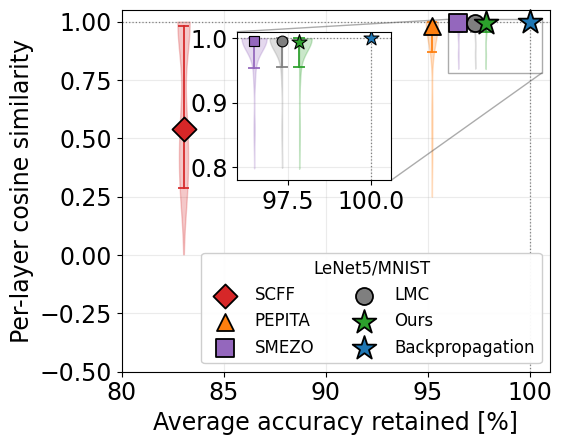

In [89]:
table = layer_cosine_table("lenet5_mnist", "LeNet5/MNIST")
plot_layer_cosine(table, "lenet5_mnist", x_lim=(80, 101), y_lim=(-0.5, None), legend_loc="lower right",
                  cap_width=0.4, violin_width=0.6,
                  zoom=dict(x=(96.0, 100.6), y=(0.78, 1.01), at=(0.27, 0.53, 0.36, 0.41), violin_width=0.75, cap_width=0.3))

== ResNet20/CIFAR10 at sigma^2 = 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1
   SMEZO        accuracy retained   39.5% (mean of 10/10 levels, 27.4..73.6)   layer cosine: median 0.127  quartiles 0.013..0.803  (410 layer x noise values)
   LMC          accuracy retained   39.6% (mean of 10/10 levels, 25.2..82.6)   layer cosine: median 0.127  quartiles 0.013..0.804  (410 layer x noise values)
   SCFF         accuracy retained   42.5% (mean of 10/10 levels, 40.7..45.9)   layer cosine: median 0.102  quartiles 0.013..0.799  (400 layer x noise values)
   PEPITA       accuracy retained   45.8% (mean of 10/10 levels, 36.7..73.3)   layer cosine: median 0.123  quartiles 0.013..0.804  (410 layer x noise values)
   Ours         accuracy retained   66.9% (mean of 10/10 levels, 49.6..90.7)   layer cosine: median 0.704  quartiles 0.379..0.942  (410 layer x noise values)

saved /home/rahman2/GIT/BOLSTER/plots/figures/layer_cosine_vs_accuracy_resnet20_cifar10.png


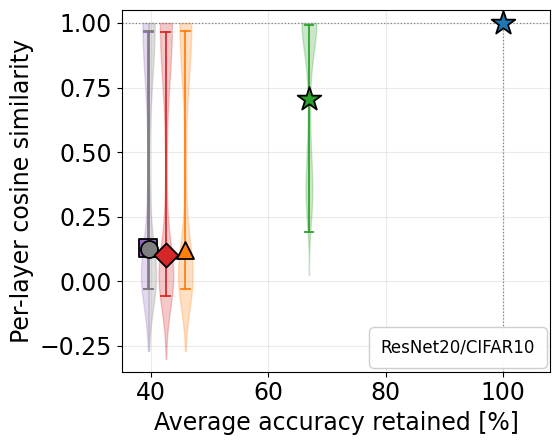

In [82]:
table = layer_cosine_table("resnet20_cifar10", "ResNet20/CIFAR10")
plot_layer_cosine(table, "resnet20_cifar10", x_lim=(35, 108), legend_loc="lower right", violin_width=2.5)

== MobileNet-v1/Tiny ImageNet at sigma^2 = 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1
   SCFF         accuracy retained    1.1% (mean of 10/10 levels, 0.9..1.6)   layer cosine: median 0.070  quartiles 0.002..0.262  (550 layer x noise values)
   SMEZO        accuracy retained   15.6% (mean of 10/10 levels, 5.2..51.3)   layer cosine: median 0.911  quartiles 0.712..0.961  (550 layer x noise values)
   PEPITA       accuracy retained   50.8% (mean of 10/10 levels, 35.5..75.3)   layer cosine: median 0.108  quartiles 0.012..0.330  (550 layer x noise values)
   LMC          accuracy retained   56.0% (mean of 10/10 levels, 33.1..88.4)   layer cosine: median 0.912  quartiles 0.710..0.961  (550 layer x noise values)
   Ours         accuracy retained   66.5% (mean of 10/10 levels, 47.4..90.6)   layer cosine: median 0.910  quartiles 0.709..0.960  (550 layer x noise values)

saved /home/rahman2/GIT/BOLSTER/plots/figures/layer_cosine_vs_accuracy_mobilenetv1_tinyimagenet.png


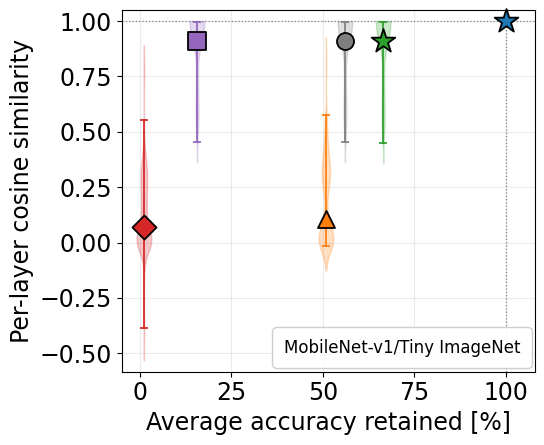

In [83]:
table = layer_cosine_table("mobilenetv1_tinyimagenet", "MobileNet-v1/Tiny ImageNet")
plot_layer_cosine(table, "mobilenetv1_tinyimagenet", x_lim=(-5, 108), legend_loc="lower right")